In [43]:
import pandas as pd
from sqlalchemy import create_engine
import statsmodels.formula.api as smf
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import rcParams
import lightgbm as lgb 
from sklearn.model_selection import train_test_split, RandomizedSearchCV, cross_validate
from sklearn.metrics import accuracy_score, classification_report, roc_auc_score, f1_score
import shap
import seaborn as sns

In [44]:
# 1. 解决中文乱码和负号显示问题（必须在画图前运行）
plt.rcParams['font.sans-serif'] = ['SimHei']  # Windows 用黑体
plt.rcParams['axes.unicode_minus'] = False

In [45]:
# 1. 填写你的 MySQL 连接信息
host = 'localhost'        # 本机
port = 3306               # 默认端口
user = 'root'             # 用户名
password = '171200416'      # 换成你自己的密码
database = 'mysql'   # 换成你自己的业务库名

# 2. 创建连接引擎
engine = create_engine(
    f'mysql+pymysql://{user}:{password}@{host}:{port}/{database}?charset=utf8mb4'
)

# 3. 读取数据（把 SQL 换成你自己的表）
sql = "SELECT * FROM 电子商务客户流失数据"
df = pd.read_sql(sql, engine)

In [46]:
df.dtypes

流失记录ID         object
客户ID           object
客户细分           object
客户国家           object
客户城市           object
是否已流失          object
流失标志            int64
流失日期           object
流失至今天数          int64
流失原因           object
流失类别           object
流失风险评分          int64
流失概率          float64
订阅类型           object
客户存续月数          int64
总消费金额(美元)     float64
平均订单金额(美元)    float64
购买次数            int64
满意度评分           int64
满意度等级          object
客服工单数           int64
退货次数            int64
距上次购买天数         int64
客户终身价值(美元)    float64
参与度水平          object
挽留措施           object
客服互动次数          int64
最近客服渠道         object
反馈评分            int64
忠诚度评分         float64
营销邮件发送数         int64
营销邮件打开数         int64
营销邮件点击数         int64
营销转化数           int64
社交媒体参与度        object
推荐次数            int64
是否高风险客户        object
预测流失           object
客户挽留成本(美元)    float64
挽回收入(美元)      float64
数据集年份          object
流失率指标          object
客户价值类别         object
流失风险类别         object
流失收入影响(美元)    float64
客户健康评分    

In [47]:
df.columns 

Index(['流失记录ID', '客户ID', '客户细分', '客户国家', '客户城市', '是否已流失', '流失标志', '流失日期',
       '流失至今天数', '流失原因', '流失类别', '流失风险评分', '流失概率', '订阅类型', '客户存续月数',
       '总消费金额(美元)', '平均订单金额(美元)', '购买次数', '满意度评分', '满意度等级', '客服工单数', '退货次数',
       '距上次购买天数', '客户终身价值(美元)', '参与度水平', '挽留措施', '客服互动次数', '最近客服渠道', '反馈评分',
       '忠诚度评分', '营销邮件发送数', '营销邮件打开数', '营销邮件点击数', '营销转化数', '社交媒体参与度', '推荐次数',
       '是否高风险客户', '预测流失', '客户挽留成本(美元)', '挽回收入(美元)', '数据集年份', '流失率指标', '客户价值类别',
       '流失风险类别', '流失收入影响(美元)', '客户健康评分', '客户健康类别', '留存概率'],
      dtype='object')

In [48]:
df["是否已流失"] = df["是否已流失"].astype(int)

In [49]:
D = df[[ '客户存续月数', '总消费金额(美元)', '购买次数', '满意度评分', '客服工单数',  '退货次数', '距上次购买天数', '客户终身价值(美元)', '客服互动次数', '营销邮件发送数', '营销邮件打开数', '营销邮件点击数', '营销转化数', '推荐次数', '客户健康评分']]


🔥 数值特征相关性热力图


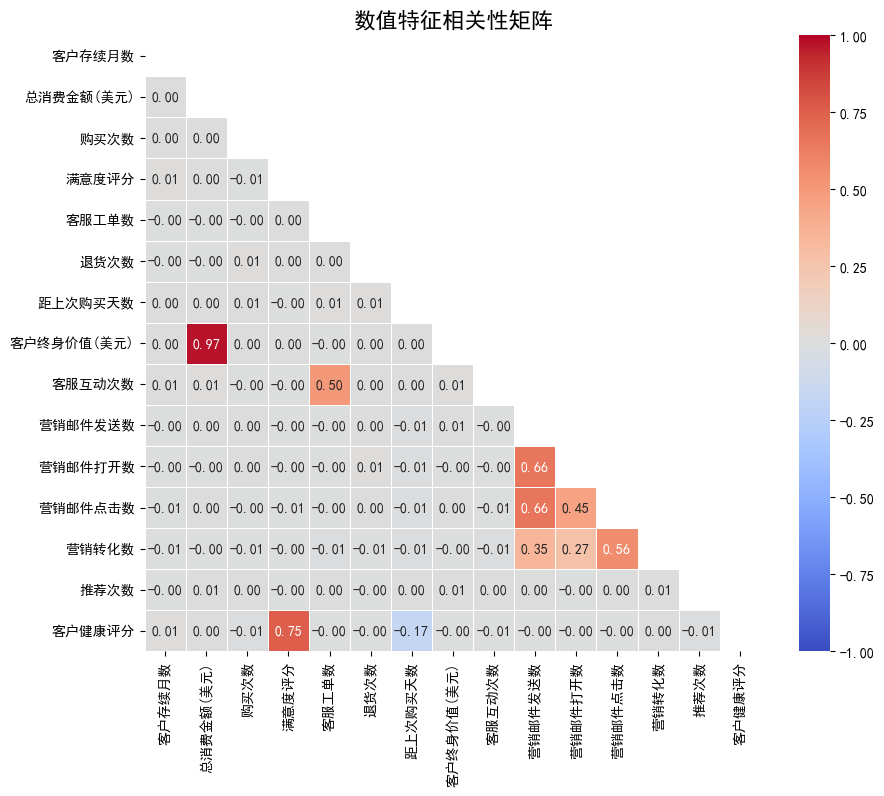

In [50]:
# 2. 确保至少有2个以上的特征才能画相关性热力图
if D.shape[1] > 1: 
    print("\n" + "=" * 60)
    print("🔥 数值特征相关性热力图")
    print("=" * 60)
    
    plt.figure(figsize=(10, 8))
    
    # 3. 对 D 计算相关系数
    corr_matrix = D.corr(method='spearman') # 建议用 spearman 防长尾干扰
    
    # 4. 画出热力图 (只显示上半三角)
    mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
    sns.heatmap(corr_matrix, mask=mask, annot=True, fmt=".2f",
                cmap='coolwarm', vmin=-1, vmax=1, center=0,
                square=True, linewidths=.5)
    
    plt.title('数值特征相关性矩阵', fontsize=16)
    plt.show()

In [51]:
F = ['客户存续月数', '总消费金额(美元)', '购买次数', '满意度评分', '客服工单数', '退货次数', '距上次购买天数', '客服互动次数', '营销邮件发送数', '营销邮件打开数', '营销邮件点击数', '营销转化数', '推荐次数']

In [52]:
if F:
    print("\n" + "=" * 60)
    print("📈 数值特征分布与偏度检测 (偏度 > 1 或 < -1 即为长尾分布)")
    print("=" * 60)
    for col in F:
        # 安全检查：只对数值型列计算偏度
        if pd.api.types.is_numeric_dtype(df[col]):
            skew = df[col].skew()
            tail_flag = ""
            if skew > 1:
                tail_flag = " ⚠️ 严重右偏(长尾)，建议对数变换(log1p)处理"
            elif skew < -1:
                tail_flag = " ⚠️ 严重左偏(长尾)"
            print(f"  - {col}: 均值={df[col].mean():.2f}, 偏度={skew:.2f}{tail_flag}")
        else:
            print(f"  - {col}: ⚠️ 非数值型特征，跳过偏度计算")
else:
    print("⚠️ 特征列表 F 为空，请检查。")


📈 数值特征分布与偏度检测 (偏度 > 1 或 < -1 即为长尾分布)
  - 客户存续月数: 均值=30.13, 偏度=-0.01
  - 总消费金额(美元): 均值=25039.36, 偏度=-0.01
  - 购买次数: 均值=24.51, 偏度=-0.00
  - 满意度评分: 均值=3.01, 偏度=-0.01
  - 客服工单数: 均值=9.41, 偏度=0.02
  - 退货次数: 均值=4.52, 偏度=-0.00
  - 距上次购买天数: 均值=99.26, 偏度=1.28 ⚠️ 严重右偏(长尾)，建议对数变换(log1p)处理
  - 客服互动次数: 均值=6.70, 偏度=0.80
  - 营销邮件发送数: 均值=24.39, 偏度=0.01
  - 营销邮件打开数: 均值=12.21, 偏度=0.97
  - 营销邮件点击数: 均值=12.26, 偏度=0.97
  - 营销转化数: 均值=3.12, 偏度=0.61
  - 推荐次数: 均值=9.49, 偏度=-0.00


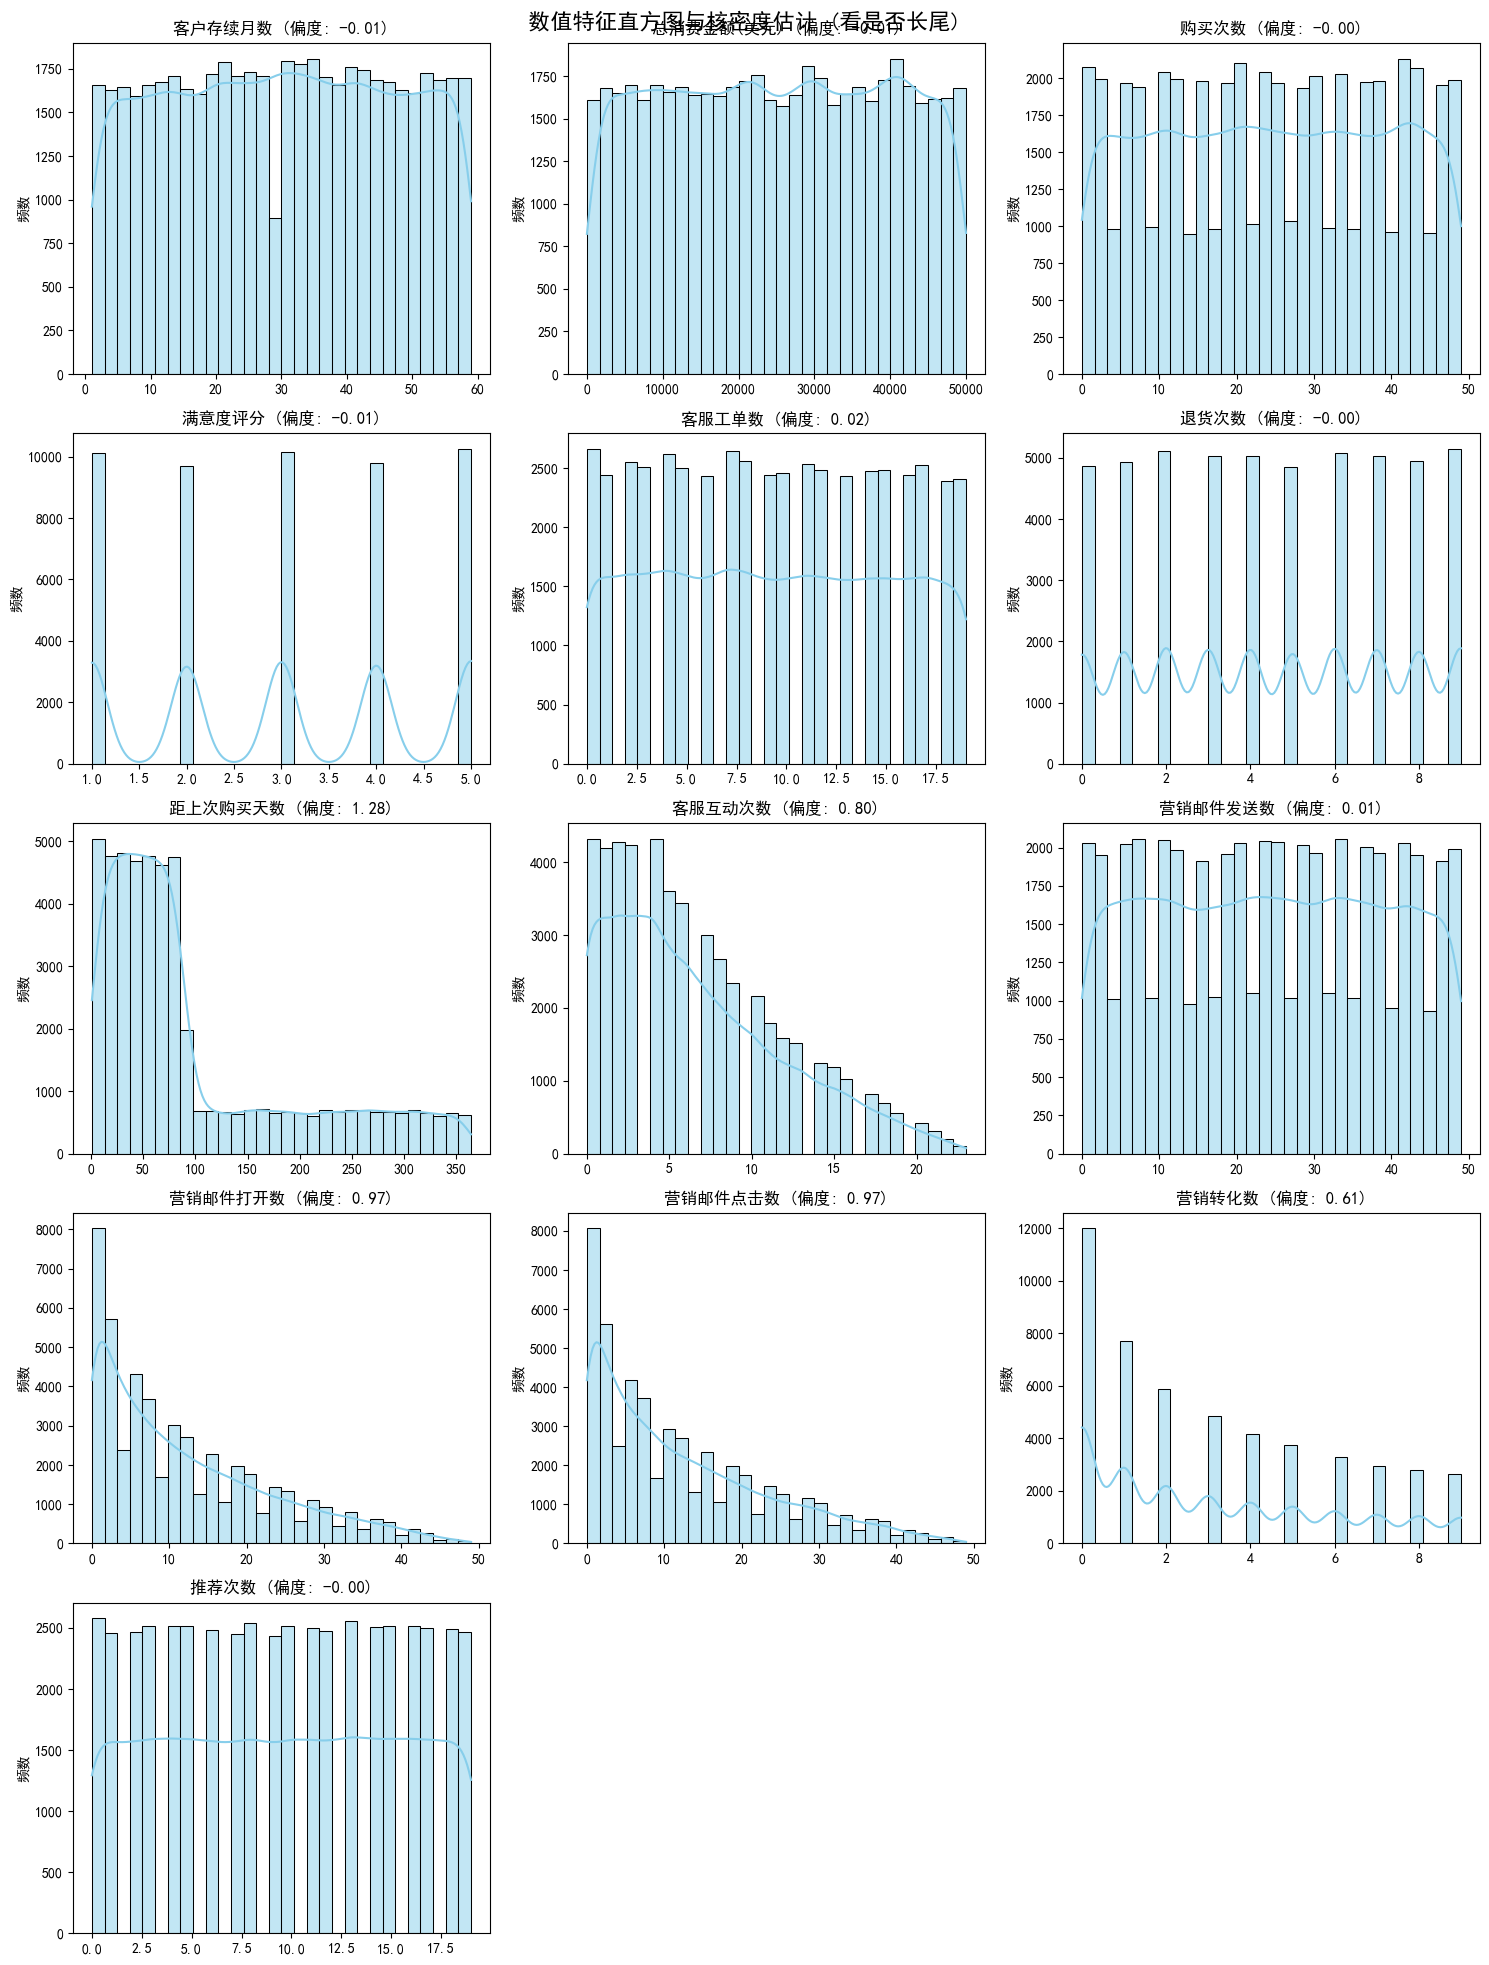

In [53]:
# 画直方图和箱线图（结合看长尾和异常值）
if F: # 确保 F 不是空的
    # 【修改点】定义每行画几个图，变量名用 n_cols，千万别覆盖了 F
    n_cols = min(3, len(F)) 
    n_rows = int(np.ceil(len(F) / n_cols))

    plt.figure(figsize=(15, 4 * n_rows))
    
    # 【修改点】遍历你的特征列表 F
    for i, col in enumerate(F):
        # 直方图看分布
        plt.subplot(n_rows, n_cols, i + 1)
        
        # 画直方图和密度曲线
        sns.histplot(df[col].dropna(), kde=True, bins=30, color='skyblue')
        
        # 标题显示特征名和偏度
        plt.title(f'{col} (偏度: {df[col].skew():.2f})')
        plt.xlabel('')
        plt.ylabel('频数')
        
    plt.suptitle("数值特征直方图与核密度估计 (看是否长尾)", fontsize=16)
    plt.tight_layout()
    plt.show()

In [54]:
X = df[['客户存续月数', '总消费金额(美元)', '购买次数', '满意度评分', '客服工单数', '退货次数', '距上次购买天数', '客服互动次数', '营销邮件发送数', '营销邮件打开数', '营销邮件点击数', '营销转化数', '推荐次数']]
Y = df['是否已流失']

In [57]:
# 2. 【核心插入点 1】：生成所有样本的权重数组
value_weights = {
    '高价值': 10.0,   
    '中价值': 3.0,
    '低价值': 1.0,
    '极低价值': 0.5
}

In [58]:
df['样本权重'] = df['客户价值类别'].map(value_weights).fillna(1.0)

In [59]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

In [60]:
train_weights = df.loc[X_train.index, '样本权重']
test_weights = df.loc[X_test.index, '样本权重'] 

In [61]:
# 【样本失衡权重计算】
neg_count = (Y_train == 0).sum()
pos_count = (Y_train == 1).sum()
scale_weight = neg_count / pos_count if pos_count > 0 else 1.0
print(f"⚖️ 样本失衡权重 (scale_pos_weight): {scale_weight:.2f}")

⚖️ 样本失衡权重 (scale_pos_weight): 1.41


In [62]:
param_grid = {
    'n_estimators': [100, 200, 300],         # 树的数量（LGBM 速度极快，可以适当增加）
    'learning_rate': [0.01, 0.05, 0.1],      # 学习率
    'num_leaves': [15, 31, 63],              # 叶子节点数（LGBM 特有的核心参数，控制树复杂度）
    'min_child_samples': [10, 20, 50],       # 叶子节点最小样本数（防过拟合）
    'subsample': [0.7, 0.9, 1.0],            # 样本采样比例
    'colsample_bytree': [0.7, 0.9, 1.0],     # 特征采样比例
    'reg_alpha': [0, 0.1, 1],                # L1 正则化
    'reg_lambda': [1, 2, 5]                  # L2 正则化
}

In [63]:
print("\n⏳ 正在使用随机搜索进行 LightGBM 模型调优...")
# 【修改点 3】实例化 LGBMClassifier
search = RandomizedSearchCV(
    lgb.LGBMClassifier(
        random_state=42,   #如果样本失衡需要处理时可加入scale_pos_weight=scale_weight这个参数
        verbose=-1  # 👈 核心：抑制 LightGBM 的警告信息
    ),
    param_distributions=param_grid,
    n_iter=20,
    cv=5,
    scoring='f1',
    n_jobs=-1,
    random_state=42,
    verbose=1
)


⏳ 正在使用随机搜索进行 LightGBM 模型调优...


In [64]:
print("⏳ 正在训练模型（加入业务权重惩罚）...")
# 【核心插入点 3】：把 train_weights 传给 fit
search.fit(
    X_train, Y_train, 
    sample_weight=train_weights  # 👈 处理 1:10:3:0.5 的价值失衡
)
print(f"\n✅ 最优参数组合: {search.best_params_}")
print(f"✅ 搜参阶段最高交叉验证 AUC: {search.best_score_:.4f}")

⏳ 正在训练模型（加入业务权重惩罚）...
Fitting 5 folds for each of 20 candidates, totalling 100 fits

✅ 最优参数组合: {'subsample': 0.7, 'reg_lambda': 2, 'reg_alpha': 0, 'num_leaves': 15, 'n_estimators': 100, 'min_child_samples': 10, 'learning_rate': 0.05, 'colsample_bytree': 0.9}
✅ 搜参阶段最高交叉验证 AUC: 0.5645


In [65]:
best_model = search.best_estimator_

In [66]:
print("\n⏳ 正在对最优模型进行 5 折交叉验证稳健性测试...")
cv_results = cross_validate(
    estimator=best_model,
    X=X_train,
    y=Y_train,
    cv=5,
    scoring=['roc_auc', 'accuracy', 'f1'],
    return_train_score=True,
    n_jobs=-1
)

test_auc = cv_results['test_roc_auc']
train_auc = cv_results['train_roc_auc']
test_acc = cv_results['test_accuracy']
test_f1 = cv_results['test_f1']

mean_auc = test_auc.mean()
std_auc = test_auc.std()
mean_acc = test_acc.mean()
mean_f1 = test_f1.mean()
overfit_gap = train_auc.mean() - mean_auc

print("="*40)
print("📊 交叉验证最终评估报告")
print("="*40)
print(f"1. 每次验证的 AUC 得分: {[round(score, 4) for score in test_auc]}")
print(f"2. 模型稳定性 (标准差): {std_auc:.4f}")
print("-" * 40)
print(f"⭐ 平均测试集 AUC: {mean_auc:.4f}")
print(f"⭐ 平均测试集 准确率: {mean_acc:.4f}")
print(f"⭐ 平均测试集 F1-score: {mean_f1:.4f}")
print(f"🔄 训练集平均 AUC: {train_auc.mean():.4f}")

if overfit_gap > 0.05:
    print(f"⚠️ 过拟合警告: 训练集比测试集高出 {overfit_gap:.4f}，建议调小 num_leaves 或增大 min_child_samples。")
else:
    print(f"✅ 泛化良好: 训练集与测试集差距仅 {overfit_gap:.4f}，模型非常稳健。")
print("="*40)


⏳ 正在对最优模型进行 5 折交叉验证稳健性测试...
📊 交叉验证最终评估报告
1. 每次验证的 AUC 得分: [np.float64(0.7201), np.float64(0.7264), np.float64(0.7135), np.float64(0.7214), np.float64(0.7119)]
2. 模型稳定性 (标准差): 0.0053
----------------------------------------
⭐ 平均测试集 AUC: 0.7187
⭐ 平均测试集 准确率: 0.6698
⭐ 平均测试集 F1-score: 0.5611
🔄 训练集平均 AUC: 0.7373
✅ 泛化良好: 训练集与测试集差距仅 0.0186，模型非常稳健。


In [67]:
y_pred = best_model.predict(X_test)
y_pred_proba = best_model.predict_proba(X_test)[:, 1]

print(f"\n🎯 最终模型在测试集的准确率 (Accuracy): {accuracy_score(Y_test, y_pred):.4f}")
print(f"🎯 最终模型的测试集 AUC 值: {roc_auc_score(Y_test, y_pred_proba):.4f}")
print(f"🎯 最终模型的少数类 F1 分数: {f1_score(Y_test, y_pred):.4f}")
print("\n分类报告:\n", classification_report(Y_test, y_pred))


🎯 最终模型在测试集的准确率 (Accuracy): 0.6748
🎯 最终模型的测试集 AUC 值: 0.7164
🎯 最终模型的少数类 F1 分数: 0.5717

分类报告:
               precision    recall  f1-score   support

           0       0.71      0.77      0.74      5923
           1       0.62      0.53      0.57      4077

    accuracy                           0.67     10000
   macro avg       0.66      0.65      0.65     10000
weighted avg       0.67      0.67      0.67     10000



In [68]:
importance_df = pd.DataFrame({
    '特征': X.columns,
    '重要性': best_model.feature_importances_
}).sort_values(by='重要性', ascending=False)
print("\n特征重要性排名:\n", importance_df)


特征重要性排名:
            特征  重要性
6     距上次购买天数  267
5        退货次数  183
4       客服工单数  181
0      客户存续月数  110
1   总消费金额(美元)  109
3       满意度评分   97
2        购买次数   90
9     营销邮件打开数   76
12       推荐次数   72
8     营销邮件发送数   67
10    营销邮件点击数   60
7      客服互动次数   53
11      营销转化数   35



⏳ 正在生成 SHAP 解释图...


D:\anaconda\Lib\site-packages\shap\explainers\_tree.py:578: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


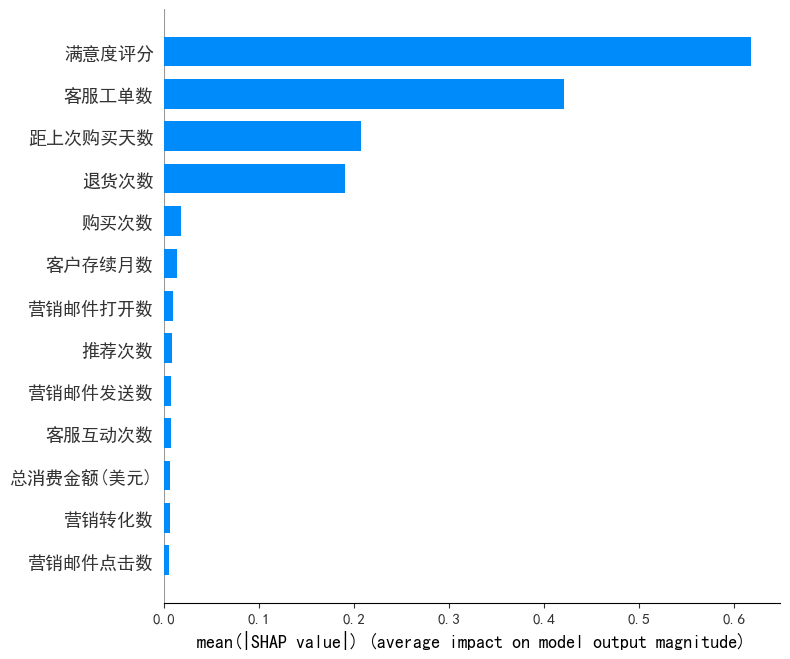

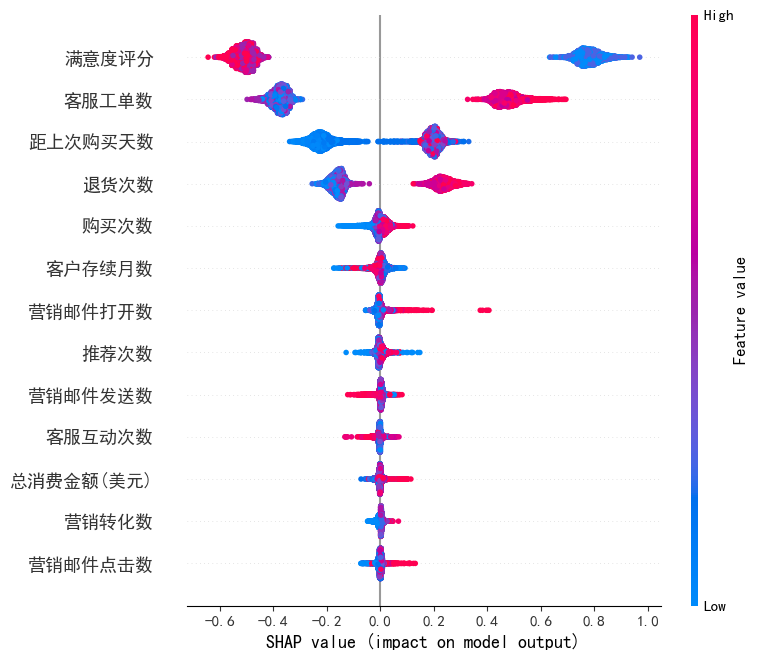

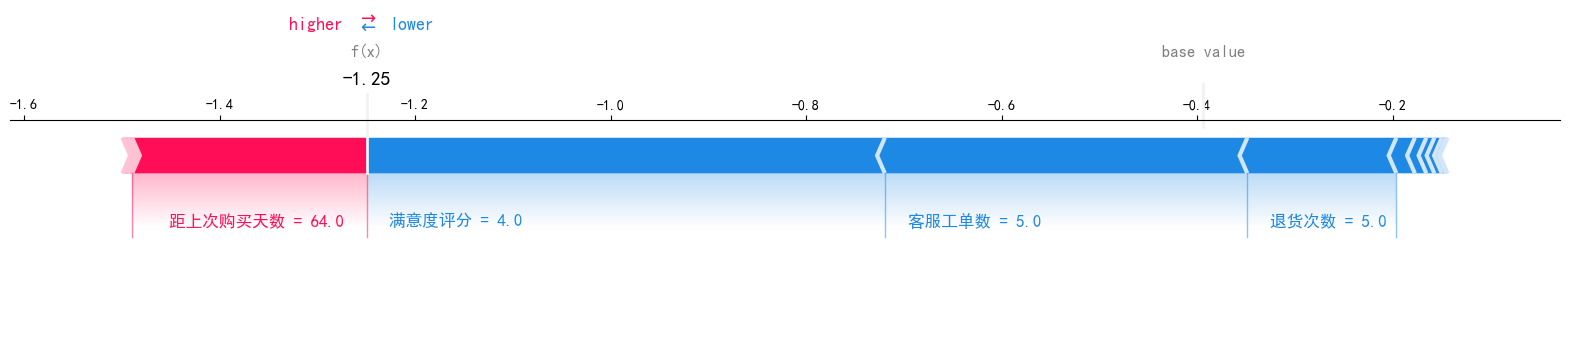

In [69]:
# 6. SHAP 解析
# ==========================================
print("\n⏳ 正在生成 SHAP 解释图...")
# SHAP 的 TreeExplainer 对 LightGBM 完美兼容
explainer = shap.TreeExplainer(best_model)
shap_values = explainer.shap_values(X_test)

# 全局特征重要性图（条形图）
shap.summary_plot(shap_values, X_test, plot_type="bar")
# 全局特征重要性图（蜂群图）
shap.summary_plot(shap_values, X_test)

# 单样本解释图
shap.force_plot(
    explainer.expected_value,
    shap_values[0,:],
    X_test.iloc[0,:],
    matplotlib=True
)

In [70]:
# 1. 确保你已经算出了测试集的预测概率
y_pred_proba = best_model.predict_proba(X_test)[:, 1]

# 2. 在原表 df 中新建一列，默认值为 NaN
df['流失率'] = np.nan

# 3. 利用 X_test 的索引，把概率精准赋值到 df 对应的行里
df.loc[X_test.index, '流失率'] = y_pred_proba

# 4. 查看结果（只看有概率的测试集部分）
print(df[df['流失率'].notna()][['客户ID', '客户价值类别', '是否已流失', '流失率']].head())

# 5. 导出为 Excel
df.to_excel(r'C:\Users\Administrator\Desktop\测试集客户流失概率预测.xlsx', index=False)

           客户ID 客户价值类别  是否已流失       流失率
4   CUST-016248    高价值      1  0.706452
6   CUST-013561    高价值      1  0.470623
7   CUST-046431    高价值      1  0.199296
38  CUST-040196    高价值      1  0.730092
40  CUST-023751    中价值      1  0.383325


In [72]:
df.columns   

Index(['流失记录ID', '客户ID', '客户细分', '客户国家', '客户城市', '是否已流失', '流失标志', '流失日期',
       '流失至今天数', '流失原因', '流失类别', '流失风险评分', '流失概率', '订阅类型', '客户存续月数',
       '总消费金额(美元)', '平均订单金额(美元)', '购买次数', '满意度评分', '满意度等级', '客服工单数', '退货次数',
       '距上次购买天数', '客户终身价值(美元)', '参与度水平', '挽留措施', '客服互动次数', '最近客服渠道', '反馈评分',
       '忠诚度评分', '营销邮件发送数', '营销邮件打开数', '营销邮件点击数', '营销转化数', '社交媒体参与度', '推荐次数',
       '是否高风险客户', '预测流失', '客户挽留成本(美元)', '挽回收入(美元)', '数据集年份', '流失率指标', '客户价值类别',
       '流失风险类别', '流失收入影响(美元)', '客户健康评分', '客户健康类别', '留存概率', '样本权重', '流失率'],
      dtype='object')